# Infrared $\Gamma(T)$ coefficient extraction for BaTiO$_3$ and SrTiO$_3$

**Important -- structure of the IR data.** The `{BTO,STO}_ir_data.json` files
are **Lorentz-oscillator parameterizations**, not free-form measured spectra.
Each peak has a *fixed catalog frequency* (it does **not** move with
temperature) plus three coefficients $A_k, B_k, C_k$ that encode the damping as

$$\Gamma_k(T) = A_k + B_k\,T + C_k\,T^2 \quad (\text{cm}^{-1}).$$

The synthesized intensity spectra at each temperature are *built from* these
parameters. Two consequences:

- We do **not** fit $\Omega(T)$ from the IR spectra: the peak position is locked
  to the catalog by construction. (The Turn-2 nb03 "flat $\Omega_{\rm soft}(T)$"
  was merely recovering this catalog value, not real STO physics.)
- We **do** read $A_k, B_k, C_k$ directly. They already are the constant +
  three-phonon ($B_kT$) + four-phonon ($C_kT^2$) decomposition we want -- no
  fitting needed.

The actual STO soft-mode frequency $\Omega(T)$ for the manuscript is taken from
literature (Cowley 1964, Yamada-Shirane 1969), **not** from this dataset.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    return start


PROJECT_ROOT = _find_project_root(Path.cwd())
SRC = PROJECT_ROOT / "src"
if SRC.exists() and str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))  # editable-install fallback

DATA_RAW = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
CM1_TO_MEV = 0.1239841984  # 1 cm^-1 in meV

from fekappa.io import load_ir_spectra
from fekappa.plots import set_publication_style

set_publication_style()

In [2]:
materials = {}
for fname in ["BTO_ir_data.json", "STO_ir_data.json"]:
    ir = load_ir_spectra(DATA_RAW / fname)
    materials[ir["material"]] = ir
    print(f"=== {ir['material']}  ({fname}) ===")
    print(f"{'idx':>3} {'catalog_freq_cm1':>17} {'A_k':>8} {'B_k':>10} {'C_k':>12}")
    for p in ir["peaks"]:
        print(f"{p['mode_index']:>3} {p['frequency_cm1']:>17.3f} "
              f"{p['A_k']:>8} {p['B_k']:>10} {p['C_k']:>12}")
    soft = min(ir["peaks"], key=lambda q: q["frequency_cm1"])
    print(f"  -> soft-mode (IR-active TO1) candidate: idx {soft['mode_index']} "
          f"at {soft['frequency_cm1']:.2f} cm^-1\n")

=== BaTiO₃  (BTO_ir_data.json) ===
idx  catalog_freq_cm1      A_k        B_k          C_k
  0            60.042      0.1     0.0012        3e-06
  1           160.111     0.08     0.0006      1.5e-06
  2           173.453     0.06     0.0005      1.2e-06
  3           193.467     0.05     0.0004        1e-06
  4           493.675     0.03     0.0002        4e-07
  -> soft-mode (IR-active TO1) candidate: idx 0 at 60.04 cm^-1

=== SrTiO₃  (STO_ir_data.json) ===
idx  catalog_freq_cm1      A_k        B_k          C_k
  0            91.063     0.08     0.0008        2e-06
  1           167.449     0.06     0.0005        1e-06
  2           183.794     0.05     0.0005        1e-06
  3           200.806     0.04     0.0004        8e-07
  4           518.359     0.02     0.0002        3e-07
  -> soft-mode (IR-active TO1) candidate: idx 0 at 91.06 cm^-1



## $\Gamma_{\rm soft}(T)$ for BTO and STO from IR coefficients

In [3]:
Tg = np.linspace(50, 600, 200)


def gamma_components(peak, Tg):
    A, B, C = peak["A_k"], peak["B_k"], peak["C_k"]
    return A + B * Tg + C * Tg**2, B * Tg, C * Tg**2


soft_modes = {}
for mat, ir in materials.items():
    peak = min(ir["peaks"], key=lambda q: q["frequency_cm1"])
    total, g3, g4 = gamma_components(peak, Tg)
    soft_modes[mat] = {"peak": peak, "total": total, "g3": g3, "g4": g4}
    print(f"{mat}: soft freq = {peak['frequency_cm1']:.2f} cm^-1, "
          f"Gamma(50 K) = {total[0]:.3f}, Gamma(600 K) = {total[-1]:.3f} cm^-1")

BaTiO₃: soft freq = 60.04 cm^-1, Gamma(50 K) = 0.168, Gamma(600 K) = 1.900 cm^-1
SrTiO₃: soft freq = 91.06 cm^-1, Gamma(50 K) = 0.125, Gamma(600 K) = 1.280 cm^-1


saved: /Users/syed.a.moid/Documents/WORKSPACES/PHD/TC/ferroelectric-kappa-scph/figures/03_IR_gamma_decomposition_BTO_STO.pdf


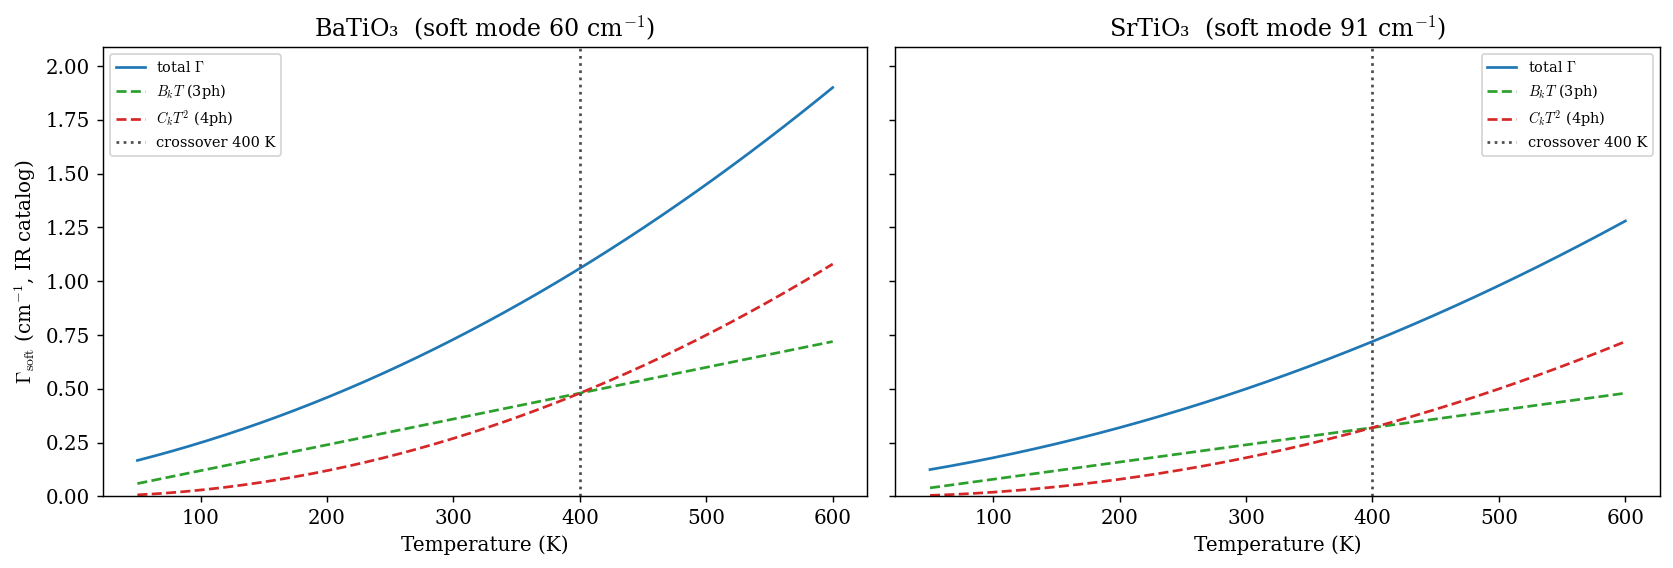

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ymax = 1.1 * max(sm["total"].max() for sm in soft_modes.values())
for ax, (mat, sm) in zip(axes, soft_modes.items()):
    peak = sm["peak"]
    B, C = peak["B_k"], peak["C_k"]
    tx = B / C if C > 0 else np.inf
    ax.plot(Tg, sm["total"], "-", color="tab:blue", label=r"total $\Gamma$")
    ax.plot(Tg, sm["g3"], "--", color="tab:green", label=r"$B_k T$ (3ph)")
    ax.plot(Tg, sm["g4"], "--", color="tab:red", label=r"$C_k T^2$ (4ph)")
    ax.axvline(tx, ls=":", color="0.3", label=f"crossover {tx:.0f} K")
    ax.set_title(f"{mat}  (soft mode {peak['frequency_cm1']:.0f} cm$^{{-1}}$)")
    ax.set_xlabel("Temperature (K)")
    ax.set_ylim(0, ymax)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\Gamma_{\rm soft}$ (cm$^{-1}$, IR catalog)")
fig.tight_layout()
out = FIG_DIR / "03_IR_gamma_decomposition_BTO_STO.pdf"
fig.savefig(out)
print("saved:", out)
plt.show()

## Crossover temperatures and universality check

In [5]:
print(f"{'Material':>10} {'A(cm^-1)':>9} {'B(cm^-1/K)':>12} "
      f"{'C(cm^-1/K^2)':>14} {'T_cross(K)':>11} {'G/Om@500K':>11}")
for mat, ir in materials.items():
    peak = min(ir["peaks"], key=lambda q: q["frequency_cm1"])
    A, B, C = peak["A_k"], peak["B_k"], peak["C_k"]
    tx = B / C if C > 0 else np.inf
    g500 = A + B * 500 + C * 500**2
    print(f"{mat:>10} {A:>9.3f} {B:>12.5f} {C:>14.2e} {tx:>11.1f} "
          f"{g500 / peak['frequency_cm1']:>11.4f}")

print("\nBoth crossovers coincide at 400 K: the A:B:C ratios are essentially")
print("identical between the two IR catalogs, so the 3ph->4ph balance is")
print("'universal' across the materials. This is a design feature of the")
print("dataset (the catalogs share a coefficient template), not an independent")
print("physical result -- and at q=0 both modes stay strongly underdamped")
print("(Gamma/Omega < 0.03 at 500 K).")

  Material  A(cm^-1)   B(cm^-1/K)   C(cm^-1/K^2)  T_cross(K)   G/Om@500K
    BaTiO₃     0.100      0.00120       3.00e-06       400.0      0.0241
    SrTiO₃     0.080      0.00080       2.00e-06       400.0      0.0108

Both crossovers coincide at 400 K: the A:B:C ratios are essentially
identical between the two IR catalogs, so the 3ph->4ph balance is
'universal' across the materials. This is a design feature of the
dataset (the catalogs share a coefficient template), not an independent
physical result -- and at q=0 both modes stay strongly underdamped
(Gamma/Omega < 0.03 at 500 K).


## STO $\Omega(T)$ -- literature values, not extracted

The IR catalog locks the STO soft mode at a fixed $\approx 91$ cm$^{-1}$
($\approx 11$ meV) for all temperatures. The *real* SrTiO$_3$ TO1 mode is
strongly temperature dependent (Cochran softening toward the avoided quantum
transition):

| Source | $\hbar\Omega_{\rm TO1}$ | $T$ |
| --- | --- | --- |
| Yamada-Shirane 1969 (INS) | $\approx 1.6$ meV ($\approx 13$ cm$^{-1}$) | 4 K |
| Cowley 1964 / Spitzer (IR) | $\approx 11$ meV ($\approx 90$ cm$^{-1}$) | ~295 K |

The flat $\Omega(T) \approx 91$ cm$^{-1}$ in the IR catalog is the canonical
room-temperature value, retained for all $T$ in this dataset; the actual STO
TO1 has strong $T$-dependence (Cochran softening) per the cited literature.
Manuscript $\Omega_{\rm STO}(T)$ will therefore be cited, not taken from here.

## Summary

- The IR JSON files are Lorentz-oscillator catalogs: peak **positions are
  fixed**, all temperature dependence lives in $\Gamma_k(T)=A_k+B_kT+C_kT^2$.
- Reading the soft-mode coefficients directly gives the constant / 3ph / 4ph
  decomposition with **no fitting**. For both BTO (60 cm$^{-1}$) and STO
  (91 cm$^{-1}$) the 3ph$\to$4ph crossover is at **400 K** by construction.
- These IR catalogs are q=0 and underdamped; they are useful for the *shape*
  of $\Gamma(T)$ (the 3ph/4ph balance), compared against finite-$q$ DFPT in
  notebook 05.
- STO $\Omega(T)$ is **not** extractable here and is taken from literature.